In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
payload_range = np.arange(1, 52)
spreading_factor_range = np.arange(7, 13)
print("Payload range: ", payload_range)
print("Spreading factor range: ", spreading_factor_range)

Payload range:  [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51]
Spreading factor range:  [ 7  8  9 10 11 12]


In [8]:
cyclic_redundancy_check = 1
header_enabled = 1
Data_rate = 0
coding_rate =4
bandwidth = 125000
results = []

for payload in payload_range:
    for spreading_factor in spreading_factor_range:
        n_packets = (8 * payload - 4 * spreading_factor + 8
                      + 16*cyclic_redundancy_check - 20 *
                        header_enabled) / (4 * (spreading_factor - 2 * Data_rate))
        n_payload = 8 + max([np.ceil(n_packets) * (coding_rate + 4), 0])
        n_messages = 8 + 4.25 + n_payload
        T_s = (2 ** spreading_factor) / bandwidth
        T_m = T_s * n_messages
        results.append((payload, spreading_factor, T_m))
        print(f"Payload: {payload}, Spreading Factor: {spreading_factor}, T_m: {T_m}")



Payload: 1, Spreading Factor: 7, T_m: 0.020735999999999997
Payload: 1, Spreading Factor: 8, T_m: 0.041471999999999995
Payload: 1, Spreading Factor: 9, T_m: 0.08294399999999999
Payload: 1, Spreading Factor: 10, T_m: 0.16588799999999998
Payload: 1, Spreading Factor: 11, T_m: 0.33177599999999996
Payload: 1, Spreading Factor: 12, T_m: 0.6635519999999999
Payload: 2, Spreading Factor: 7, T_m: 0.020735999999999997
Payload: 2, Spreading Factor: 8, T_m: 0.041471999999999995
Payload: 2, Spreading Factor: 9, T_m: 0.08294399999999999
Payload: 2, Spreading Factor: 10, T_m: 0.16588799999999998
Payload: 2, Spreading Factor: 11, T_m: 0.33177599999999996
Payload: 2, Spreading Factor: 12, T_m: 0.6635519999999999
Payload: 3, Spreading Factor: 7, T_m: 0.020735999999999997
Payload: 3, Spreading Factor: 8, T_m: 0.041471999999999995
Payload: 3, Spreading Factor: 9, T_m: 0.08294399999999999
Payload: 3, Spreading Factor: 10, T_m: 0.16588799999999998
Payload: 3, Spreading Factor: 11, T_m: 0.33177599999999996
Pa

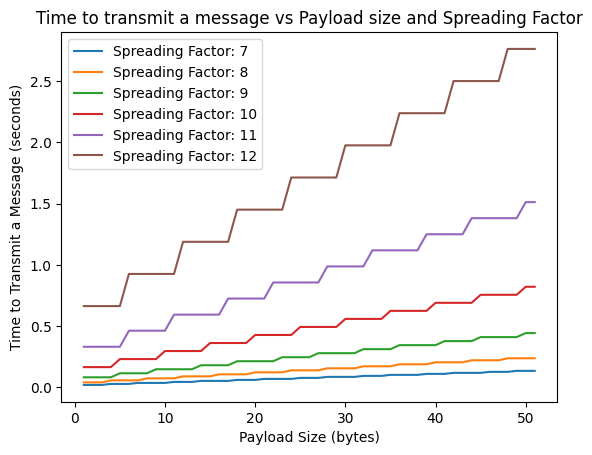

In [9]:
plt.Figure(figsize=(10, 6))
plt.title("Time to transmit a message vs Payload size and Spreading Factor")
for spreading_factor in spreading_factor_range:
    T_m_values = [result[2] for result in results if result[1] == spreading_factor]
    plt.plot(payload_range, T_m_values, label=f"Spreading Factor: {spreading_factor}")
plt.xlabel("Payload Size (bytes)")
plt.ylabel("Time to Transmit a Message (seconds)")
plt.legend()

In [15]:
#simulate transmission of 300 messages with spreading factor 7 and repeat 500 times
spreading_factor = 7
n_messages = 300

In [13]:
def calculate_transmission_time(payload, spreading_factor):
    cyclic_redundancy_check = 1
    header_enabled = 1
    Data_rate = 0
    coding_rate = 4
    bandwidth = 125000

    n_packets = (8 * payload - 4 * spreading_factor + 8
                  + 16*cyclic_redundancy_check - 20 *
                    header_enabled) / (4 * (spreading_factor - 2 * Data_rate))
    n_payload = 8 + max([np.ceil(n_packets) * (coding_rate + 4), 0])
    n_messages = 8 + 4.25 + n_payload
    T_s = (2 ** spreading_factor) / bandwidth
    T_m = T_s * n_messages
    return T_m

In [27]:
#simulate transmission function
def simulate_transmission_collisions(spreading_factor, n_messages, payload):
    #get transmission start time
    t_start = np.random.uniform(0,1000, n_messages)
    #calculate time on air for each message
    T_m = calculate_transmission_time(payload, spreading_factor)
    #calculate transmission end time for each message
    t_end = t_start + T_m
    #check for collisions
    #get all intervals
    all_intervals = pd.IntervalIndex.from_arrays(t_start, t_end, closed='both')
    collisionArray = np.zeros(len(t_start))
    #iterate through array
    for i in range(len(t_start)):
        overlap_list = all_intervals.overlaps(pd.Interval(t_start[i], t_end[i]))
        if np.sum(overlap_list) > 1:
            collisionArray[i] = 1
        else:
            collisionArray[i] = 0
    #calculate number of collisions
    n_collisions = np.sum(collisionArray)
    #calculate percentage of collisions
    percentage_collisions = (n_collisions / n_messages) * 100
    return percentage_collisions


In [37]:
#simulate transmission of 300 messages with spreading factor 7 and repeat 500 times
n_repeats = 500
all_collision_results = {}
for spreading_factor in [7, 10, 12]:
    collision_results = []
    for i in range(n_repeats):
        collision_percentage = simulate_transmission_collisions(spreading_factor, n_messages, payload=20)
        collision_results.append(collision_percentage)
    all_collision_results[spreading_factor] = collision_results



In [34]:
#print the results of the simulation
for spreading_factor, collision_results in all_collision_results.items():
    print(f"Spreading Factor: {spreading_factor}, Average Collision Percentage: {np.mean(collision_results)}")

Spreading Factor: 7, Average Collision Percentage: 3.5506666666666664
Spreading Factor: 10, Average Collision Percentage: 22.593333333333337
Spreading Factor: 12, Average Collision Percentage: 58.004


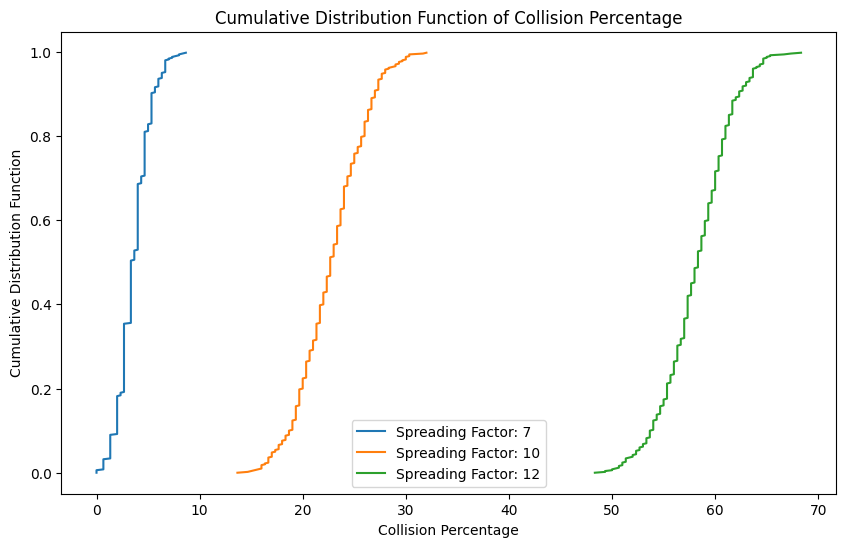

In [38]:
#plot the results of the simulation with 7, 10 and 12 spreading factors
#convert the result to cumulative distribution function
plt.figure(figsize=(10, 6))
for spreading_factor, collision_results in all_collision_results.items():
    sorted_results = np.sort(collision_results)
    cdf = np.arange(len(sorted_results)) / float(len(sorted_results))
    plt.plot(sorted_results, cdf, label=f"Spreading Factor: {spreading_factor}")
plt.title("Cumulative Distribution Function of Collision Percentage")
plt.xlabel("Collision Percentage")
plt.ylabel("Cumulative Distribution Function")
plt.legend()